In [1]:
import numpy as np
import pandas as pd

from pathlib import Path
import os
os.environ['FUTSPREAD_ROOT'] = '/Users/robli/Documents/Columbia/2026Fall/DDF/data/futspread'

from futspread import enumerate_specs, liquid_months, build_combo, load_combo
from futspread.universe import POINT_VALUE

from src.backtest import *
from src.strategies import *
from src.metrics import *

In [2]:
combos = build_combos()

In [17]:
final = backtest(combos, t_stat, windows, '2021-01-01', '2025-12-31')   # your chosen rule, once                                # Q1(b)

daily = daily_pnl(final, combos)
tbl = q2_table(daily, final).round(4)
tbl

,G Return,G Vol,G Sharpe,G MaxDD,N Return,N Vol,N Sharpe,N MaxDD,Trades,Won,Cost/gross
2021,0.0005,0.0026,0.2068,-0.0030,0.0003,0.0026,0.1075,-0.0030,5.0,0.60,0.4777
2022,0.0052,0.0038,1.3576,-0.0016,0.0049,0.0038,1.2953,-0.0017,5.0,0.60,0.0495
2023,-0.0008,0.0033,-0.2479,-0.0029,-0.0011,0.0033,-0.3242,-0.0031,5.0,0.60,-0.3120
2024,-0.0010,0.0027,-0.3604,-0.0023,-0.0012,0.0027,-0.4545,-0.0024,5.0,0.20,-0.2670
2025,0.0008,0.0016,0.4941,-0.0010,0.0006,0.0016,0.3405,-0.0010,5.0,0.60,0.3128
2021–2025,0.0010,0.0029,0.3298,-0.0037,0.0007,0.0029,0.2414,-0.0040,25.0,0.52,0.2675


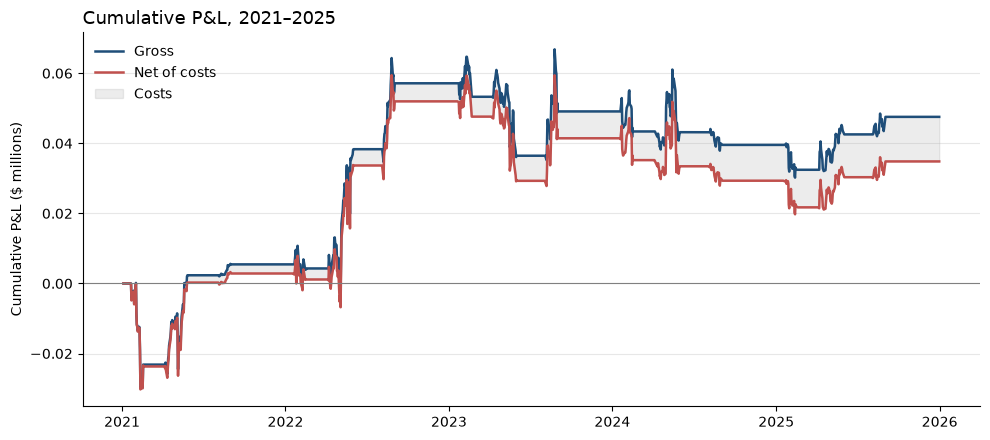

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ---- settings ----
FIGSIZE   = (10, 4.5)
COLOURS   = {'gross': '#1f4e79', 'net': '#c0504d'}
LABELS    = {'gross': 'Gross', 'net': 'Net of costs'}
LINEWIDTH = 1.8
TITLE     = 'Cumulative P&L, 2021–2025'
SCALE, UNIT = 1e6, '$ millions'      # use 1e3, '$ thousands' if the numbers are small

cum = daily[['gross', 'net']].cumsum() / SCALE

fig, ax = plt.subplots(figsize=FIGSIZE)
for col in ['gross', 'net']:
    ax.plot(cum.index, cum[col], color=COLOURS[col], lw=LINEWIDTH, label=LABELS[col])

ax.axhline(0, color='grey', lw=0.8)                      # zero line
ax.fill_between(cum.index, cum['gross'], cum['net'],
                color='grey', alpha=0.15, label='Costs')  # gap = cumulative costs
ax.set_title(TITLE, fontsize=13, loc='left')
ax.set_ylabel(f'Cumulative P&L ({UNIT})')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.2f}'))
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)           # remove the box
ax.legend(frameon=False, loc='upper left')

fig.tight_layout()
plt.show()

In [15]:
tbl.to_csv('results/q2_table.csv')        # full precision; opens in Excel

fig.savefig('results/q2_cum_pnl.png', dpi=200, bbox_inches='tight')